In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.7 MB/s eta 0:00:00


In [3]:
import numpy as np
import wfdb
import matplotlib.pyplot as plt

In [4]:
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")

In [5]:
def charger_ecg(nom, duree_s=10, voie=0):
    fin = None if duree_s is None else int(duree_s * 360)
    record = wfdb.rdrecord(nom, pn_dir='mitdb', sampto=fin)
    annot = wfdb.rdann(nom, 'atr', pn_dir='mitdb', sampto=fin)

    x = record.p_signal[:, voie]
    fs = record.fs

    garder = [i for i, s in enumerate(annot.symbol) if s in BEAT_SYMBOLS]
    pos = annot.sample[garder]
    types = [annot.symbol[i] for i in garder]
    return x, fs, pos, types

In [6]:
def ms_vers_echantillons(duree_ms, fs):
    n = int(round(duree_ms / 1000 * fs))
    n = max(n, 1)
    return n if n % 2 == 1 else n + 1

fs = 360 Hz | durée = 10.0 s
nombre de battements annotés : 13
200 ms = 73 échantillons
16 ms  = 7 échantillons


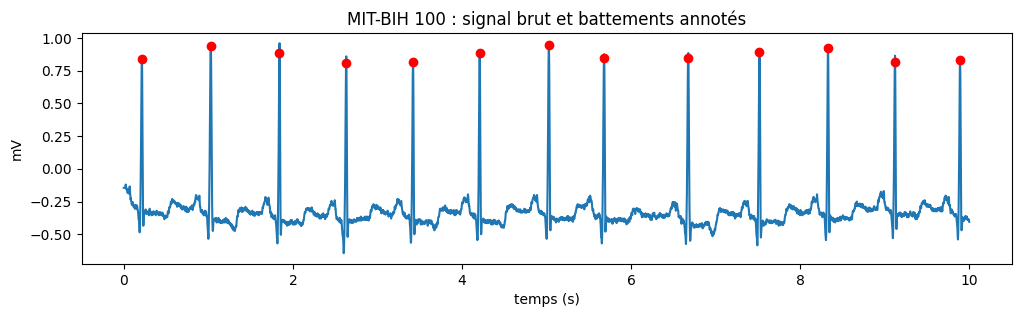

In [7]:
x, fs, pos, types = charger_ecg('100', duree_s=10)
t = np.arange(len(x)) / fs

print("fs =", fs, "Hz | durée =", len(x) / fs, "s")
print("nombre de battements annotés :", len(pos))
print("200 ms =", ms_vers_echantillons(200, fs), "échantillons")
print("16 ms  =", ms_vers_echantillons(16, fs), "échantillons")

plt.figure(figsize=(12, 3))
plt.plot(t, x)
plt.plot(t[pos], x[pos], 'ro')
plt.xlabel("temps (s)"); plt.ylabel("mV")
plt.title("MIT-BIH 100 : signal brut et battements annotés")
plt.show()

In [8]:
def erosion(x, n):
    r = n // 2
    xp = np.pad(x, r, mode='edge')
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = xp[i:i + n].min()
    return out

In [9]:
def dilatation(x, n):
    r = n // 2
    xp = np.pad(x, r, mode='edge')
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = xp[i:i + n].max()
    return out

signal     : [0. 0. 5. 0. 0. 0. 3. 3. 3. 3. 3. 0. 0. 0.]
érosion    : [0. 0. 0. 0. 0. 0. 0. 3. 3. 3. 0. 0. 0. 0.]
dilatation : [0. 5. 5. 5. 0. 3. 3. 3. 3. 3. 3. 3. 0. 0.]


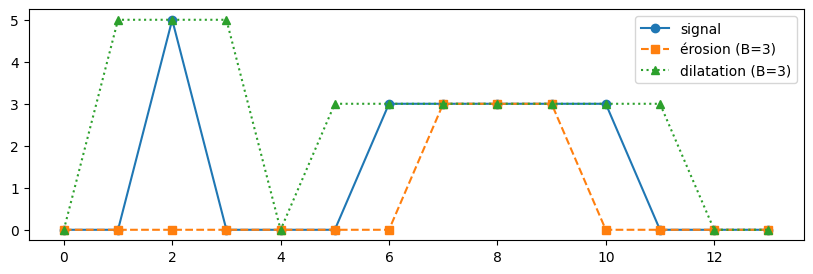

In [10]:
s = np.array([0, 0, 5, 0, 0, 0, 3, 3, 3, 3, 3, 0, 0, 0], dtype=float)

print("signal     :", s)
print("érosion    :", erosion(s, 3))
print("dilatation :", dilatation(s, 3))

plt.figure(figsize=(10, 3))
plt.plot(s, 'o-', label="signal")
plt.plot(erosion(s, 3), 's--', label="érosion (B=3)")
plt.plot(dilatation(s, 3), '^:', label="dilatation (B=3)")
plt.legend(); plt.show()

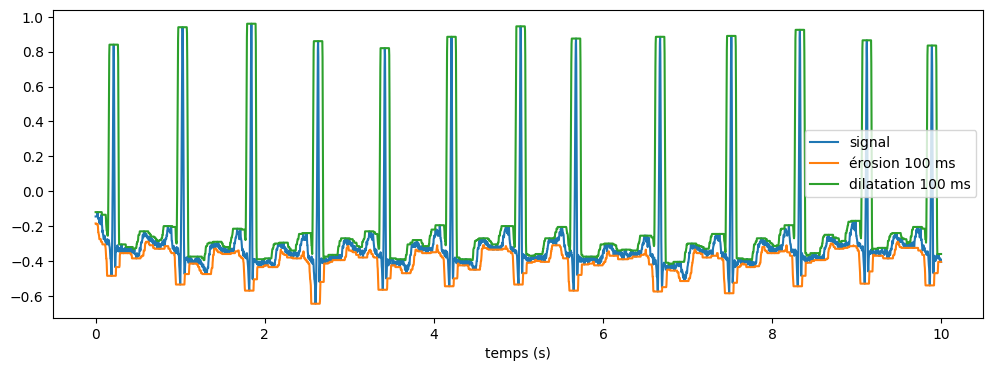

In [11]:
n = ms_vers_echantillons(100, fs)
ero = erosion(x, n)
dil = dilatation(x, n)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal")
plt.plot(t, ero, label="érosion 100 ms")
plt.plot(t, dil, label="dilatation 100 ms")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [12]:
def ouverture(x, n):
    return dilatation(erosion(x, n), n)

In [13]:
def fermeture(x, n):
    return erosion(dilatation(x, n), n)

signal    : [0. 0. 5. 0. 0. 0. 3. 3. 3. 3. 3. 0. 0. 0.]
ouverture : [0. 0. 0. 0. 0. 0. 3. 3. 3. 3. 3. 0. 0. 0.]
fermeture : [0. 0. 5. 0. 0. 0. 3. 3. 3. 3. 3. 0. 0. 0.]


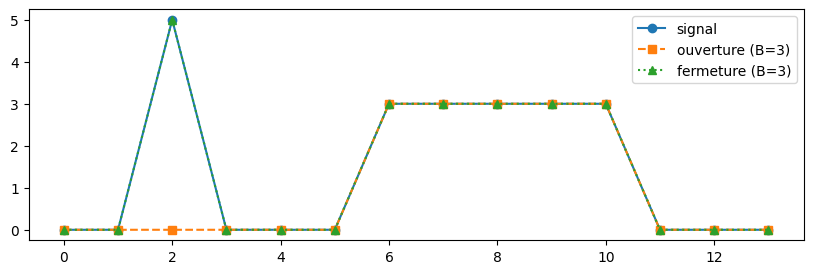

In [14]:
print("signal    :", s)
print("ouverture :", ouverture(s, 3))
print("fermeture :", fermeture(s, 3))

plt.figure(figsize=(10, 3))
plt.plot(s, 'o-', label="signal")
plt.plot(ouverture(s, 3), 's--', label="ouverture (B=3)")
plt.plot(fermeture(s, 3), '^:', label="fermeture (B=3)")
plt.legend(); plt.show()

In [15]:
s2 = np.array([3, 3, 3, 0, 3, 3, 3, 3], dtype=float)
print("signal    :", s2)
print("fermeture :", fermeture(s2, 3))

signal    : [3. 3. 3. 0. 3. 3. 3. 3.]
fermeture : [3. 3. 3. 3. 3. 3. 3. 3.]


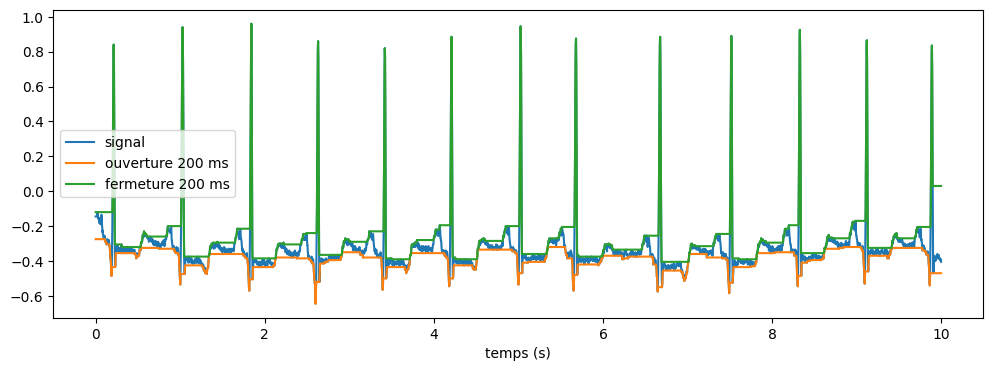

In [16]:
n = ms_vers_echantillons(200, fs)
ouv = ouverture(x, n)
fer = fermeture(x, n)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal")
plt.plot(t, ouv, label="ouverture 200 ms")
plt.plot(t, fer, label="fermeture 200 ms")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [17]:
def enlever_derive(x, fs, b1_ms=200, b2_ms=300):
    n1 = ms_vers_echantillons(b1_ms, fs)
    n2 = ms_vers_echantillons(b2_ms, fs)
    base = fermeture(ouverture(x, n1), n2)
    return x - base, base

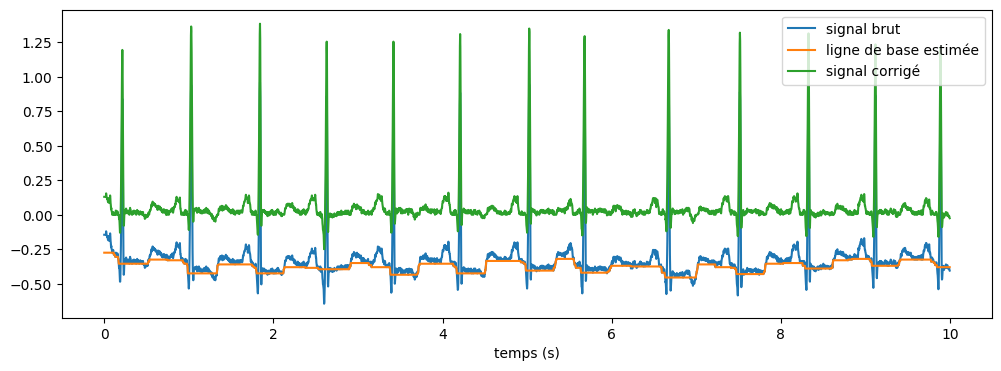

In [18]:
x_clean, base = enlever_derive(x, fs)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal brut")
plt.plot(t, base, label="ligne de base estimée")
plt.plot(t, x_clean, label="signal corrigé")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

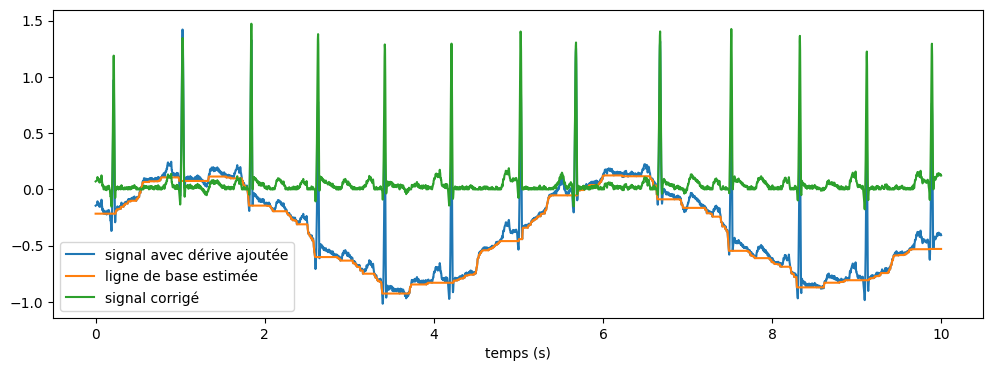

In [19]:
derive = 0.5 * np.sin(2 * np.pi * 0.2 * t)   # dérive lente, 0,2 Hz
x_derive = x + derive

x_corr, base2 = enlever_derive(x_derive, fs)

plt.figure(figsize=(12, 4))
plt.plot(t, x_derive, label="signal avec dérive ajoutée")
plt.plot(t, base2, label="ligne de base estimée")
plt.plot(t, x_corr, label="signal corrigé")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [20]:
def enlever_bruit(x, fs, b_ms=16):
    n = ms_vers_echantillons(b_ms, fs)
    a = fermeture(ouverture(x, n), n)
    b = ouverture(fermeture(x, n), n)
    return (a + b) / 2

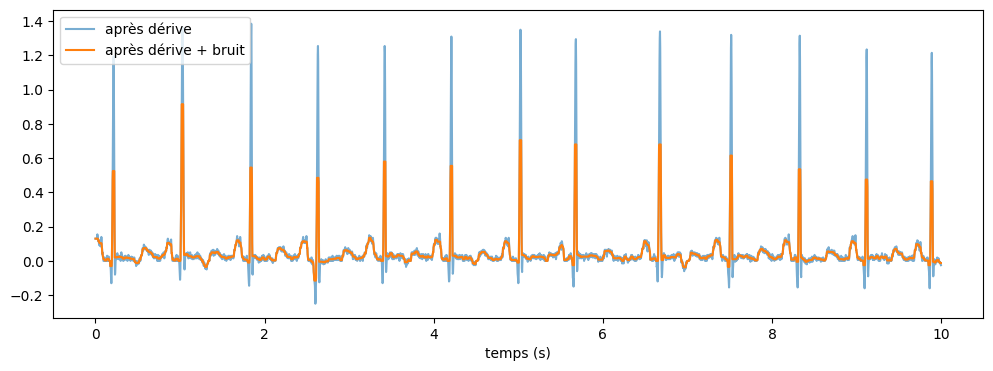

In [21]:
x_net = enlever_bruit(x_clean, fs)

plt.figure(figsize=(12, 4))
plt.plot(t, x_clean, label="après dérive", alpha=0.6)
plt.plot(t, x_net, label="après dérive + bruit")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

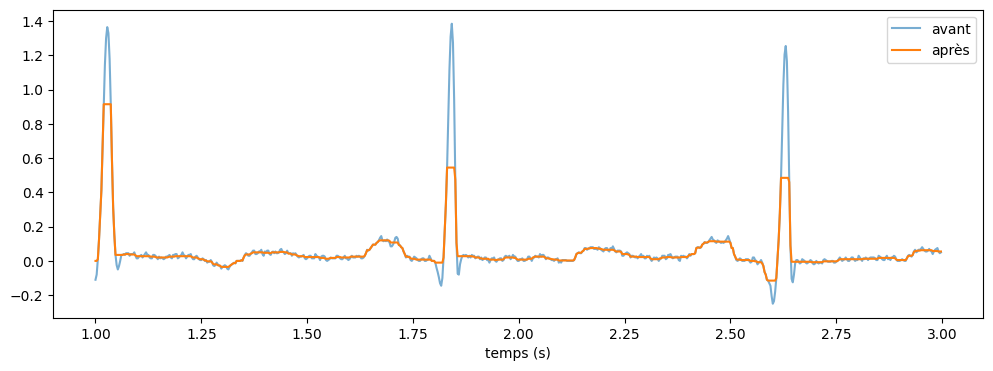

In [22]:
a, b = int(1 * fs), int(3 * fs)

plt.figure(figsize=(12, 4))
plt.plot(t[a:b], x_clean[a:b], label="avant", alpha=0.6)
plt.plot(t[a:b], x_net[a:b], label="après")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

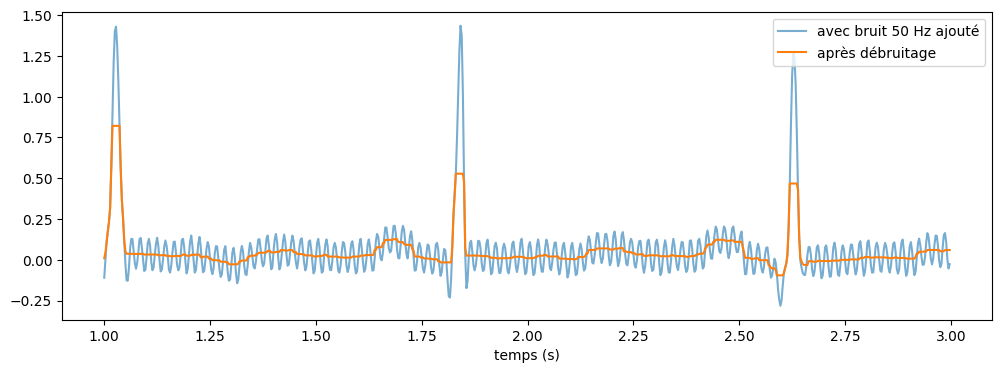

erreur avant : 0.06350029057089679
erreur après : 0.0228655294104755


In [23]:
bruit = 0.1 * np.sin(2 * np.pi * 50 * t)
x_bruite = x_clean + bruit
x_rep = enlever_bruit(x_bruite, fs)

plt.figure(figsize=(12, 4))
plt.plot(t[a:b], x_bruite[a:b], label="avec bruit 50 Hz ajouté", alpha=0.6)
plt.plot(t[a:b], x_rep[a:b], label="après débruitage")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

print("erreur avant :", np.abs(x_bruite - x_clean).mean())
print("erreur après :", np.abs(x_rep - x_clean).mean())

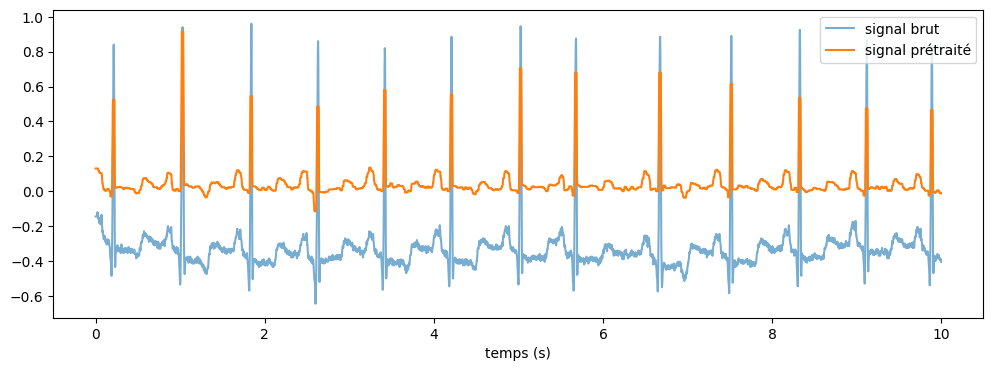

In [24]:
def pretraiter(x, fs):
    x_sans_derive, base = enlever_derive(x, fs)
    return enlever_bruit(x_sans_derive, fs)

x_final = pretraiter(x, fs)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal brut", alpha=0.6)
plt.plot(t, x_final, label="signal prétraité")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [25]:
def tophat_blanc(x, n):
    return x - ouverture(x, n)

def tophat_noir(x, n):
    return fermeture(x, n) - x

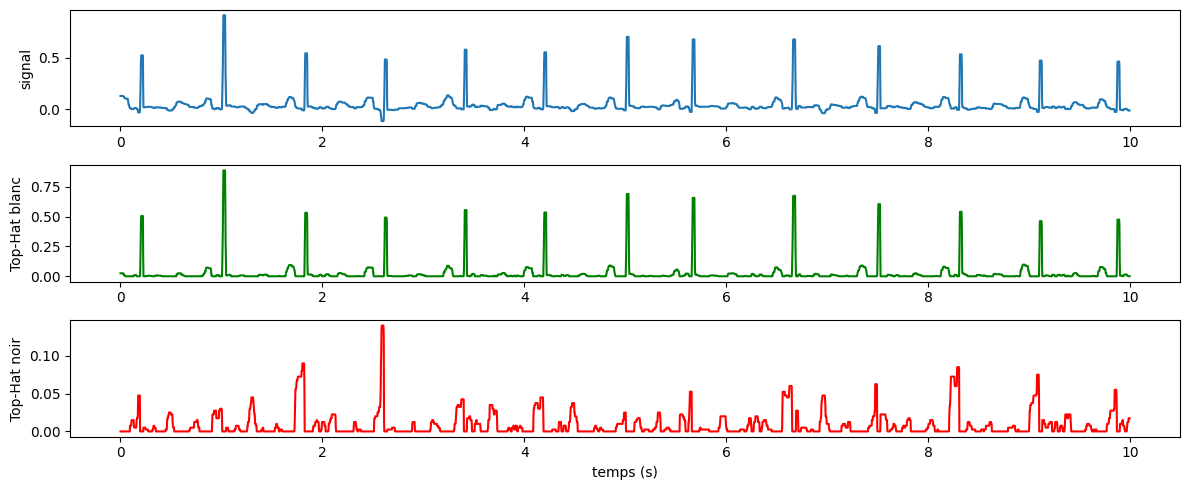

In [26]:
n = ms_vers_echantillons(100, fs)

th_b = tophat_blanc(x_final, n)
th_n = tophat_noir(x_final, n)

plt.figure(figsize=(12, 5))
plt.subplot(3, 1, 1)
plt.plot(t, x_final); plt.ylabel("signal")
plt.subplot(3, 1, 2)
plt.plot(t, th_b, color="green"); plt.ylabel("Top-Hat blanc")
plt.subplot(3, 1, 3)
plt.plot(t, th_n, color="red"); plt.ylabel("Top-Hat noir")
plt.xlabel("temps (s)"); plt.tight_layout(); plt.show()

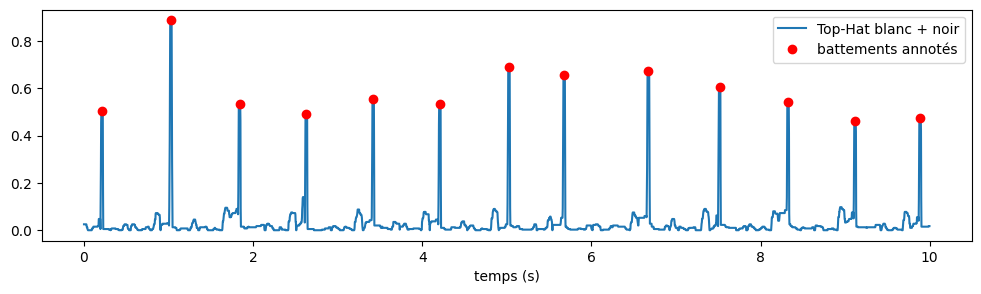

In [27]:
rehausse = th_b + th_n

plt.figure(figsize=(12, 3))
plt.plot(t, rehausse, label="Top-Hat blanc + noir")
plt.plot(t[pos], rehausse[pos], 'ro', label="battements annotés")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

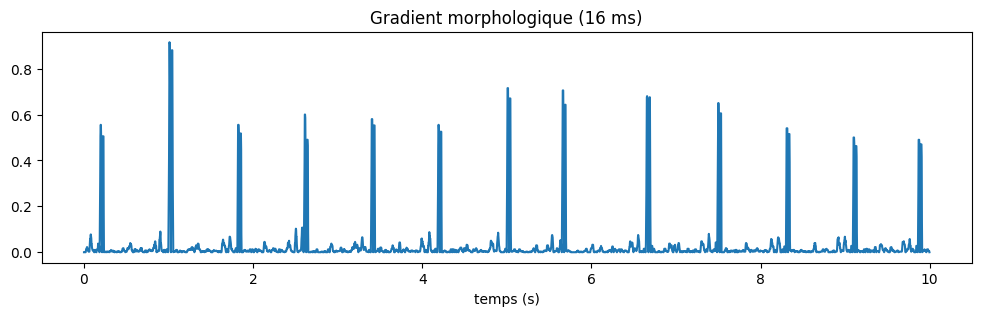

In [28]:
def gradient(x, n):
    return dilatation(x, n) - erosion(x, n)

grad = gradient(x_final, ms_vers_echantillons(16, fs))

plt.figure(figsize=(12, 3))
plt.plot(t, grad)
plt.xlabel("temps (s)"); plt.title("Gradient morphologique (16 ms)"); plt.show()

In [29]:
def detecter_qrs(rehausse, fs, ratio=0.3, refractaire_ms=200):
    seuil = ratio * rehausse.max()
    refractaire = int(refractaire_ms / 1000 * fs)

    candidats = np.where(rehausse > seuil)[0]
    detectes = []
    i = 0
    while i < len(candidats):
        debut = candidats[i]
        fin = debut + refractaire
        zone = candidats[(candidats >= debut) & (candidats < fin)]
        pic = zone[np.argmax(rehausse[zone])]
        detectes.append(pic)
        i += len(zone)
    return np.array(detectes)

battements annotés : 13
battements détectés : 13


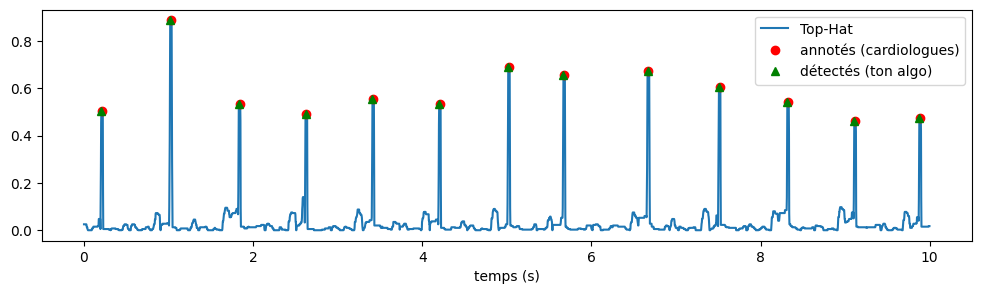

In [30]:
detectes = detecter_qrs(rehausse, fs)

print("battements annotés :", len(pos))
print("battements détectés :", len(detectes))

plt.figure(figsize=(12, 3))
plt.plot(t, rehausse, label="Top-Hat")
plt.plot(t[pos], rehausse[pos], 'ro', label="annotés (cardiologues)")
plt.plot(t[detectes], rehausse[detectes], 'g^', label="détectés (ton algo)")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [31]:
def evaluer(detectes, pos, fs, tol_ms=150):
    tol = int(tol_ms / 1000 * fs)
    vrais_pos = 0
    for d in detectes:
        if np.any(np.abs(pos - d) <= tol):
            vrais_pos += 1
    faux_pos = len(detectes) - vrais_pos
    faux_neg = len(pos) - vrais_pos
    se = vrais_pos / (vrais_pos + faux_neg)
    vpp = vrais_pos / (vrais_pos + faux_pos)
    return se, vpp, vrais_pos, faux_pos, faux_neg

se, vpp, tp, fp, fn = evaluer(detectes, pos, fs)
print(f"Sensibilité (Se) = {se:.3f}")
print(f"Précision (VPP)  = {vpp:.3f}")
print(f"Vrais positifs = {tp} | Faux positifs = {fp} | Faux négatifs = {fn}")

Sensibilité (Se) = 1.000
Précision (VPP)  = 1.000
Vrais positifs = 13 | Faux positifs = 0 | Faux négatifs = 0


In [32]:
erosion_lente = erosion
dilatation_lente = dilatation

In [33]:
from scipy.ndimage import minimum_filter1d, maximum_filter1d

def erosion(x, n):
    return minimum_filter1d(x, size=n, mode='nearest')

def dilatation(x, n):
    return maximum_filter1d(x, size=n, mode='nearest')

In [34]:
n = ms_vers_echantillons(100, fs)

print("érosion identique    :", np.allclose(erosion_lente(x, n), erosion(x, n)))
print("dilatation identique :", np.allclose(dilatation_lente(x, n), dilatation(x, n)))

érosion identique    : True
dilatation identique : True


In [35]:
import time

long = np.tile(x, 100)

t0 = time.time()
r = erosion(long, n)
print("version rapide :", round(time.time() - t0, 4), "s")

t0 = time.time()
r = erosion_lente(x, n)
duree_lente = time.time() - t0
print("version lente sur 10 s seulement :", round(duree_lente, 4), "s")
print("estimation lente sur 1000 s      :", round(duree_lente * 100, 1), "s")

version rapide : 0.0101 s
version lente sur 10 s seulement : 0.0078 s
estimation lente sur 1000 s      : 0.8 s


In [36]:
x_final2 = pretraiter(x, fs)
n100 = ms_vers_echantillons(100, fs)
rehausse2 = tophat_blanc(x_final2, n100) + tophat_noir(x_final2, n100)
detectes2 = detecter_qrs(rehausse2, fs)

se, vpp, tp, fp, fn = evaluer(detectes2, pos, fs)
print(f"Se = {se:.3f} | VPP = {vpp:.3f} | TP = {tp} FP = {fp} FN = {fn}")

Se = 1.000 | VPP = 1.000 | TP = 13 FP = 0 FN = 0


In [37]:
def pipeline_qrs(x, fs, ratio=0.3, th_ms=100):
    x_prop = pretraiter(x, fs)
    n = ms_vers_echantillons(th_ms, fs)
    rehausse = tophat_blanc(x_prop, n) + tophat_noir(x_prop, n)
    return detecter_qrs(rehausse, fs, ratio=ratio), rehausse

In [38]:
detectes3, _ = pipeline_qrs(x, fs)
se, vpp, tp, fp, fn = evaluer(detectes3, pos, fs)
print(f"Se = {se:.3f} | VPP = {vpp:.3f} | TP = {tp} FP = {fp} FN = {fn}")

Se = 1.000 | VPP = 1.000 | TP = 13 FP = 0 FN = 0


In [39]:
x101, fs101, pos101, types101 = charger_ecg('101', duree_s=None)

print("durée :", round(len(x101) / fs101 / 60, 1), "min")
print("échantillons :", len(x101))
print("battements annotés :", len(pos101))

durée : 30.1 min
échantillons : 650000
battements annotés : 1865


In [40]:
t0 = time.time()
det101, _ = pipeline_qrs(x101, fs101)
print("temps de calcul :", round(time.time() - t0, 1), "s")

se, vpp, tp, fp, fn = evaluer(det101, pos101, fs101)
print(f"Se = {se:.3f} | VPP = {vpp:.3f} | TP = {tp} FP = {fp} FN = {fn}")

temps de calcul : 0.2 s
Se = 0.999 | VPP = 1.000 | TP = 1863 FP = 0 FN = 2


In [41]:
tol = int(0.150 * fs101)

rates = [p for p in pos101 if not np.any(np.abs(det101 - p) <= tol)]
print("positions des battements ratés (en secondes) :", [round(p / fs101, 1) for p in rates])
for p in rates:
    i = list(pos101).index(p)
    print(f"  t = {p / fs101:.1f} s | type annoté = {types101[i]}")

positions des battements ratés (en secondes) : [np.float64(85.2), np.float64(175.9)]
  t = 85.2 s | type annoté = N
  t = 175.9 s | type annoté = N


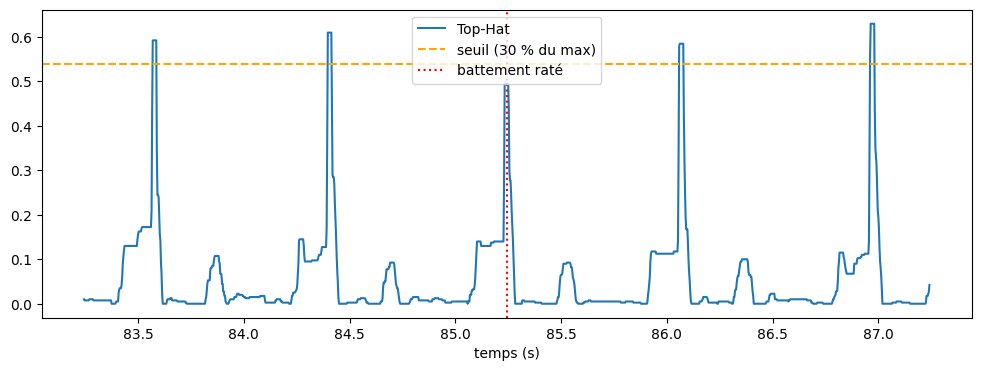

In [42]:
p = rates[0]
a, b = max(p - int(2 * fs101), 0), min(p + int(2 * fs101), len(x101))
_, reh101 = pipeline_qrs(x101, fs101)

plt.figure(figsize=(12, 4))
plt.plot(np.arange(a, b) / fs101, reh101[a:b], label="Top-Hat")
plt.axhline(0.3 * reh101.max(), color="orange", linestyle="--", label="seuil (30 % du max)")
plt.axvline(p / fs101, color="red", linestyle=":", label="battement raté")
plt.xlabel("temps (s)"); plt.legend(); plt.show()

In [43]:
from scipy.ndimage import maximum_filter1d

def detecter_qrs_local(rehausse, fs, ratio=0.3, fenetre_s=5, refractaire_ms=200):
    n = int(fenetre_s * fs) | 1
    seuil = ratio * maximum_filter1d(rehausse, size=n, mode='nearest')
    refractaire = int(refractaire_ms / 1000 * fs)

    candidats = np.where(rehausse > seuil)[0]
    detectes = []
    i = 0
    while i < len(candidats):
        debut = candidats[i]
        zone = candidats[(candidats >= debut) & (candidats < debut + refractaire)]
        detectes.append(zone[np.argmax(rehausse[zone])])
        i += len(zone)
    return np.array(detectes)

In [44]:
det_local = detecter_qrs_local(reh101, fs101)

se, vpp, tp, fp, fn = evaluer(det_local, pos101, fs101)
print(f"Seuil local  : Se = {se:.3f} | VPP = {vpp:.3f} | TP = {tp} FP = {fp} FN = {fn}")

se, vpp, tp, fp, fn = evaluer(det101, pos101, fs101)
print(f"Seuil global : Se = {se:.3f} | VPP = {vpp:.3f} | TP = {tp} FP = {fp} FN = {fn}")

Seuil local  : Se = 0.999 | VPP = 1.000 | TP = 1864 FP = 0 FN = 1
Seuil global : Se = 0.999 | VPP = 1.000 | TP = 1863 FP = 0 FN = 2


In [45]:
DS1 = ['101','106','108','109','112','114','115','116','118','119','122',
       '124','201','203','205','207','208','209','215','220','223','230']

In [46]:
donnees_ds1 = {}
for nom in DS1:
    try:
        donnees_ds1[nom] = charger_ecg(nom, duree_s=None)
    except Exception as e:
        print("échec", nom, ":", e)

print(len(donnees_ds1), "enregistrements chargés")

22 enregistrements chargés


In [47]:
def traiter_enregistrement(x, fs, pos, th_ms=100, ratio=0.3):
    # 1) nettoyage : retire la dérive de la ligne de base et le bruit rapide
    x_prop = pretraiter(x, fs)

    # 2) rehaussement : le Top-Hat blanc + noir ne garde que ce qui est
    #    plus étroit que th_ms (100 ms), donc les QRS
    n = ms_vers_echantillons(th_ms, fs)
    reh = tophat_blanc(x_prop, n) + tophat_noir(x_prop, n)

    # 3) détection : seuil local sur 5 s + période réfractaire de 200 ms
    det = detecter_qrs_local(reh, fs, ratio=ratio)

    # 4) évaluation : compare avec les annotations des cardiologues
    se, vpp, tp, fp, fn = evaluer(det, pos, fs)

    return reh, det, se, vpp, tp, fp, fn

In [48]:
import time

resultats = {}      # nom -> (se, vpp, tp, fp, fn)
rehausses = {}      # nom -> signal rehaussé
detections = {}     # nom -> positions des QRS détectés
TP_tot = FP_tot = FN_tot = 0

t0 = time.time()
for nom, (x, fs, pos, types) in donnees_ds1.items():
    reh, det, se, vpp, tp, fp, fn = traiter_enregistrement(x, fs, pos)

    resultats[nom] = (se, vpp, tp, fp, fn)
    rehausses[nom] = reh
    detections[nom] = det

    TP_tot += tp
    FP_tot += fp
    FN_tot += fn

    print(f"{nom} terminé ({time.time() - t0:.0f} s) | Se={se:.3f} VPP={vpp:.3f}")

print("\nTerminé.")

101 terminé (0 s) | Se=0.999 VPP=1.000
106 terminé (1 s) | Se=1.007 VPP=0.961
108 terminé (1 s) | Se=1.299 VPP=0.876
109 terminé (2 s) | Se=0.998 VPP=1.000
112 terminé (2 s) | Se=1.000 VPP=0.999
114 terminé (2 s) | Se=0.938 VPP=0.587
115 terminé (3 s) | Se=1.000 VPP=1.000
116 terminé (3 s) | Se=0.993 VPP=0.998
118 terminé (4 s) | Se=1.000 VPP=0.998
119 terminé (4 s) | Se=1.000 VPP=0.998
122 terminé (4 s) | Se=1.000 VPP=1.000
124 terminé (5 s) | Se=0.998 VPP=1.000
201 terminé (5 s) | Se=0.994 VPP=0.910
203 terminé (5 s) | Se=0.963 VPP=0.940
205 terminé (6 s) | Se=0.998 VPP=0.997
207 terminé (6 s) | Se=0.989 VPP=0.810
208 terminé (7 s) | Se=0.994 VPP=0.993
209 terminé (7 s) | Se=1.001 VPP=0.988
215 terminé (8 s) | Se=0.957 VPP=0.877
220 terminé (8 s) | Se=1.000 VPP=1.000
223 terminé (8 s) | Se=0.995 VPP=1.000
230 terminé (9 s) | Se=1.000 VPP=0.998

Terminé.
